# Depth-conditioned transcriptomic field synthesis

**Depth -> complete splat field -> rendered expression.** This experiment optimizes the rendered field, not correspondence to fitted reference splats. Learned slot embeddings identify output primitives; a shared network conditions on section depth and emits centers, scales, rotations, molecular latents, and amplitudes. A frozen shared decoder converts the emitted latents into expression profiles.

No per-section splat inventories, program labels, reference centers, or geometry losses are used as targets. Initialization uses training observations only. The held-out field is emitted from depth alone; measurement coordinates are supplied only to query and evaluate that field.

This is deterministic, specimen-specific conditional synthesis/interpolation. It is not free-text prompting, population-level simulation, or sampling biological variability. Five registered training sections cannot establish those broader capabilities.

## Data and artifacts

Reuse the registered pilot's cohort configuration, coordinate transform/source metadata, and frozen training autoencoder via `SOURCE_RUN_ID`. No other notebook session, fitted reference splat files, or program vocabulary is needed. The loader verifies the original observation IDs and coordinates. Atlas registration is externally supplied and molecular-informed.

Targets are the released nonnegative **log2 expression signals**, not raw molecule counts. The normalized decoder profiles describe the composition of those signals. Existing notebooks and outputs remain unchanged.


In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import torch
from dotenv import load_dotenv
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / 'pyproject.toml').exists() and (PROJECT_ROOT / 'spatsplat').is_dir()):
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError('Cannot locate repository root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT / '.env')
from paper.latent_arrangement import load_reference_cohort, load_encoder, load_array_record
from paper.conditional_field import (
    initialize_from_observations, ConditionalSplatGenerator, CoordinateMLP, StaticVolume,
    train_field, predict_field, field_metrics, export_field,
)
from paper.splat_arrangement import seed_all
from spatsplat.baselines.knn import KNNCountRegressor

pd.options.display.float_format = lambda value: f'{value:.4g}'
np.set_printoptions(precision=4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


Device: cuda


In [2]:
SOURCE_RUN_ID = 'ffa25daacf'
SOURCE_DIR = PROJECT_ROOT / 'notebooks' / 'checkpoints' / 'splat_arrangement' / SOURCE_RUN_ID
CONFIG = {
    'num_splats': 256, 'kernel_sharpness': 0.5, 'width': 128, 'slot_dim': 32,
    'steps': 10000, 'checkpoint_every': 500, 'batch_size': 512, 'learning_rate': 1e-3,
    'model_seeds': [3107, 3117], 'initialization_seed': 3107,
    'cosine_weight': 0.25, 'total_weight': 0.1,
    'support_weight': 0.05, 'support_radius': 0.03,
    'validation_measurements': 1024, 'validation_seed': 8307,
    'knn_candidates': [8, 32, 128],
    'models': ['Conditional splats', 'Volumetric splats', 'MLP-MAE', 'MLP (Bio Objective)'],
    'selection': 'validation subset cosine, then MAE; earliest exact tie',
    'field_loss': 'training-scaled MAE + fixed cosine/log-total weights; no curriculum',
}
REUSE_CHECKPOINTS = True
RUN_TEST = True
source_config = json.loads((SOURCE_DIR / 'config.json').read_text())
sections = source_config['retained_sections']
validation_section = f"C57BL6J-638850.{source_config['validation_suffix']}"
test_section = f"C57BL6J-638850.{source_config['test_suffix']}"
train_sections = [s for s in sections if s not in [validation_section, test_section]]
source_hash = hashlib.sha256()
for name in ['config.json', 'coordinate_transform.npz', 'coordinate_source.json', 'autoencoder.pt']:
    source_hash.update(name.encode())
    source_hash.update((SOURCE_DIR / name).read_bytes())
code_hash = hashlib.sha256()
for path in ['paper/conditional_field.py', 'paper/latent_arrangement.py', 'spatsplat/models.py',
             'spatsplat/volumetric.py', 'spatsplat/autoencoder.py', 'spatsplat/baselines/mlp.py',
             'spatsplat/baselines/knn.py', 'spatsplat/analysis.py']:
    code_hash.update((PROJECT_ROOT / path).read_bytes())
manifest = dict(config=CONFIG, source_run=SOURCE_RUN_ID, source_sha256=source_hash.hexdigest(),
                code_sha256=code_hash.hexdigest(), workflow_version=1)
run_id = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = PROJECT_ROOT / 'notebooks' / 'checkpoints' / 'conditional_field_synthesis' / run_id
FIGURE_DIR = PROJECT_ROOT / 'figures' / 'conditional_field_synthesis-allen_merfish-mouse_brain' / run_id
RUN_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2))
def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=200, bbox_inches='tight', facecolor='white')
print(json.dumps(manifest, indent=2))
print(f'Artifacts: {RUN_DIR}')


{
  "config": {
    "num_splats": 256,
    "kernel_sharpness": 0.5,
    "width": 128,
    "slot_dim": 32,
    "steps": 10000,
    "checkpoint_every": 500,
    "batch_size": 512,
    "learning_rate": 0.001,
    "model_seeds": [
      3107,
      3117
    ],
    "initialization_seed": 3107,
    "cosine_weight": 0.25,
    "total_weight": 0.1,
    "support_weight": 0.05,
    "support_radius": 0.03,
    "validation_measurements": 1024,
    "validation_seed": 8307,
    "knn_candidates": [
      8,
      32,
      128
    ],
    "models": [
      "Conditional splats",
      "Volumetric splats",
      "MLP-MAE",
      "MLP (Bio Objective)"
    ],
    "selection": "validation subset cosine, then MAE; earliest exact tie",
    "field_loss": "training-scaled MAE + fixed cosine/log-total weights; no curriculum"
  },
  "source_run": "ffa25daacf",
  "source_sha256": "6e8ed42a8a28890ec607a7b6269ca24e9ed6038bc028da0f4818fc7b3e73db6c",
  "code_sha256": "5b0f91f6fc57d76fda2ace9974da86258c8225361f88599852

## Training-only initialization

Reuse only the frozen autoencoder, not any section's fitted splat inventory. Spatially spread template centers come from training measurements. Their initial latents encode neighboring training profiles, and their initial amplitudes come from neighboring training totals.

The conditional generator starts with the same template at every depth, then learns depth-specific changes through the field objective. Centers stay within the training bounding rectangle and scales have explicit bounds. A soft support penalty tolerates a radius around sampled training observations; it is not a validated tissue segmentation or a guarantee of held-out containment.

The static 3D baseline uses the library's restricted-rotation volumetric field. Its support penalty checks xy against the nearest training section without attracting z coordinates onto observed planes. A 256-splat static volume and 256 emitted splats per depth are not equivalent parameter/storage budgets; this is a same-data comparison, not a budget-matched claim.


In [3]:
cohort, gene_names = load_reference_cohort(SOURCE_DIR)
autoencoder = load_encoder(SOURCE_DIR / 'autoencoder.pt', device)
if autoencoder.decoder.gene_head.out_features != len(gene_names):
    raise ValueError('Autoencoder gene dimension does not match the source expression matrix')
transform = load_array_record(SOURCE_DIR / 'coordinate_transform.npz')
depth_metric_scale = float(transform['z_scale']/transform['coordinate_scale'])
training = [dict(section=s, xy=cohort[s]['xy'], expression=cohort[s]['expression'],
                 depth=float(cohort[s]['depth'])) for s in train_sections]
train_xy = np.concatenate([d['xy'] for d in training])
train_values = np.concatenate([d['expression'] for d in training])
train_xyz = np.concatenate([np.column_stack((d['xy'], np.full(len(d['xy']), d['depth'], dtype=np.float32)))
                            for d in training]).astype(np.float32)
init2d = initialize_from_observations(train_xy, train_values, autoencoder,
                                     num_splats=CONFIG['num_splats'], seed=CONFIG['initialization_seed'])
init3d = initialize_from_observations(train_xyz, train_values, autoencoder,
                                     num_splats=CONFIG['num_splats'], seed=CONFIG['initialization_seed'])
for name, initialization in [('2d', init2d), ('3d', init3d)]:
    np.savez_compressed(RUN_DIR / f'initialization_{name}.npz',
                        **{k: v.numpy() for k, v in initialization.items()})
val_rng = np.random.default_rng(CONFIG['validation_seed'])
val_data = cohort[validation_section]
val_indices = np.sort(val_rng.choice(len(val_data['xy']),
    min(CONFIG['validation_measurements'], len(val_data['xy'])), replace=False))
np.save(RUN_DIR / 'validation_indices.npy', val_indices)
validation = dict(section=validation_section, xy=val_data['xy'][val_indices],
                  expression=val_data['expression'][val_indices], depth=float(val_data['depth']))
constant_rate = train_values.mean(0)
# Gene examples and color limits are chosen from training targets only.
plot_gene_indices = np.argsort(train_values.var(0))[-4:][::-1]
plot_gene_limits = np.maximum(np.quantile(train_values[:, plot_gene_indices], 0.99, axis=0), 1e-6)
display(pd.DataFrame([dict(section=s, z=cohort[s]['z'], measurements=len(cohort[s]['xy']),
                          role='validation' if s == validation_section else 'test' if s == test_section else 'train')
                      for s in sections]))
print('Training-selected example genes:', ', '.join(gene_names[plot_gene_indices]))


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20260415/manifest.json. A more up to date version of the dataset -- releases/20260711/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20260415/manifest.json', 'releases/20260711/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20260711/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


,section,z,measurements,role
0,C57BL6J-638850.19,3.6,6000,train
1,C57BL6J-638850.24,3.8,6000,train
2,C57BL6J-638850.25,4,6000,validation
3,C57BL6J-638850.26,4.2,6000,train
4,C57BL6J-638850.28,4.6,6000,train
5,C57BL6J-638850.29,4.8,6000,test
6,C57BL6J-638850.30,5,6000,train


Training-selected example genes: ENSMUSG00000070570, ENSMUSG00000053025, ENSMUSG00000027347, ENSMUSG00000038530


## Fit fields, not splat correspondences

The conditional and volumetric splats use training-scaled MAE plus fixed cosine and log-total terms, with a soft training-support penalty. There is no late cosine curriculum. The MLP biological-objective control uses the same expression terms; MLP-MAE uses only MAE. A coordinate MLP evaluates a field directly rather than emitting splats.

Sample sections uniformly, then measurements within the chosen section. At checkpoints, render the fixed validation subset and select maximum cosine, then minimum MAE. Do not select seeds using test results. Periodic and selected checkpoints are stored separately, with explicit cache messages.

Rendering the conditional field uses the library's 2D amplitude-splat responsibilities through differentiable functional parameter substitution. The frozen decoder still propagates gradients into emitted molecular latents. Training targets are exclusively observed expression, not a teacher splat arrangement.


Loading completed field: conditional_splats_3107_best.pt
Loading completed field: conditional_splats_3117_best.pt
Loading completed field: volumetric_splats_3107_best.pt
Loading completed field: volumetric_splats_3117_best.pt
Loading completed field: mlp-mae_3107_best.pt
Loading completed field: mlp-mae_3117_best.pt
Loading completed field: mlp_bio_objective_3107_best.pt
Loading completed field: mlp_bio_objective_3117_best.pt


,model,seed,selected_step,trainable_parameters,stored_tensor_mib
0,Conditional splats,3107,9500,33958,0.5521
1,Conditional splats,3117,4000,33958,0.5521
2,Volumetric splats,3107,500,10240,0.3903
3,Volumetric splats,3117,500,10240,0.3903
4,MLP-MAE,3107,10000,87974,0.3356
5,MLP-MAE,3117,9500,87974,0.3356
6,MLP (Bio Objective),3107,9500,87974,0.3356
7,MLP (Bio Objective),3117,9000,87974,0.3356


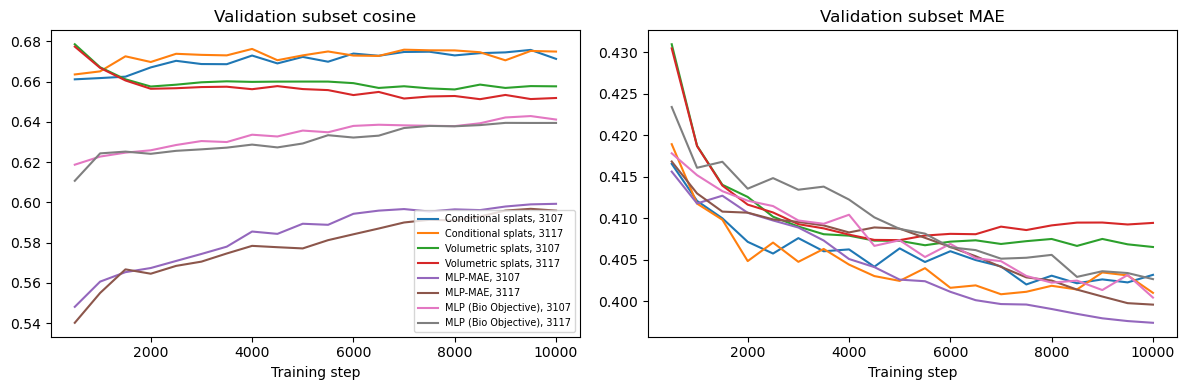

In [4]:
def build_model(kind, seed):
    seed_all(seed)
    if kind == 'Conditional splats':
        model = ConditionalSplatGenerator(init2d, autoencoder.decoder, width=CONFIG['width'],
                    slot_dim=CONFIG['slot_dim'], kernel_sharpness=CONFIG['kernel_sharpness'])
    elif kind == 'Volumetric splats':
        model = StaticVolume(init3d, autoencoder.decoder, kernel_sharpness=CONFIG['kernel_sharpness'])
    else:
        model = CoordinateMLP(len(gene_names), width=CONFIG['width'], depth_metric_scale=depth_metric_scale,
                              loss_mode='mae' if kind == 'MLP-MAE' else 'bio')
    return model.to(device)

models, histories, parameter_rows = {}, {}, []
for kind in CONFIG['models']:
    slug = kind.lower().replace(' ', '_').replace('(', '').replace(')', '')
    for seed in CONFIG['model_seeds']:
        path = RUN_DIR / f'{slug}_{seed}_best.pt'
        model = build_model(kind, seed)
        if REUSE_CHECKPOINTS and path.exists():
            print(f'Loading completed field: {path.name}', flush=True)
            saved = torch.load(path, map_location=device, weights_only=True)
            model.load_state_dict(saved['state_dict'])
            fit = saved['fit']
        else:
            print(f'Training fresh: {kind}, seed {seed}', flush=True)
            def checkpoint(current, history):
                torch.save({'state_dict': current.state_dict(), 'step': history[-1]['step']},
                           RUN_DIR / f'{slug}_{seed}_step_{history[-1]["step"]:06d}.pt')
                pd.DataFrame(history).to_csv(RUN_DIR / f'{slug}_{seed}_history.csv', index=False)
            fit = train_field(
                model, training, validation, steps=CONFIG['steps'], batch_size=CONFIG['batch_size'],
                checkpoint_every=CONFIG['checkpoint_every'], lr=CONFIG['learning_rate'], seed=seed,
                cosine_weight=CONFIG['cosine_weight'], total_weight=CONFIG['total_weight'],
                support_weight=CONFIG['support_weight'], support_radius=CONFIG['support_radius'],
                on_checkpoint=checkpoint)
            torch.save({'state_dict': model.state_dict(), 'fit': fit}, path)
        model.eval()
        models[kind, seed] = model
        histories[kind, seed] = fit['history']
        parameter_rows.append(dict(model=kind, seed=seed, selected_step=fit['best_step'],
                                   trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
                                   stored_tensor_mib=sum(t.numel()*t.element_size() for t in model.state_dict().values())/2**20))
display(pd.DataFrame(parameter_rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (kind, seed), rows in histories.items():
    history = pd.DataFrame(rows)
    axes[0].plot(history.step, history.profile_cosine, label=f'{kind}, {seed}')
    axes[1].plot(history.step, history.expression_mae, label=f'{kind}, {seed}')
for ax, title in zip(axes, ['Validation subset cosine', 'Validation subset MAE']):
    ax.set(title=title, xlabel='Training step')
axes[0].legend(fontsize=7)
fig.tight_layout()
save_figure(fig, 'validation_learning_curves')
plt.show()


## Spatial KNN and constant expression

KNN uses training observations only and inverse-distance weighting in xyz. Its z distances are converted into the same physical scaling as normalized xy, rather than treating normalized anatomical depth as an arbitrary equal-length axis. Choose K on the same validation subset; do not tune it on test.

The constant baseline is the mean training expression vector, not a mean derived from a held-out inventory. Unlike the previous rearrangement experiments, none of these models receives held-out profiles.


In [5]:
knn_training_xyz = train_xyz.copy()
knn_training_xyz[:, 2] *= depth_metric_scale
knn = KNNCountRegressor(
    torch.as_tensor(knn_training_xyz, dtype=torch.float32, device=device),
    torch.as_tensor(train_values, dtype=torch.float32, device=device), k=CONFIG['knn_candidates'][0]).to(device)
def knn_prediction(xy, depth):
    rows = []
    with torch.no_grad():
        for start in range(0, len(xy), CONFIG['batch_size']):
            query = np.column_stack((xy[start:start+CONFIG['batch_size']],
                                     np.full(min(CONFIG['batch_size'], len(xy)-start), depth*depth_metric_scale)))
            rows.append(knn(torch.as_tensor(query, dtype=torch.float32, device=device)).exp().cpu().numpy())
    return np.concatenate(rows)
knn_rows = []
for k in CONFIG['knn_candidates']:
    knn.k = k
    scores = field_metrics(knn_prediction(validation['xy'], validation['depth']), validation['expression'])
    knn_rows.append(dict(k=k, **scores))
knn_selection = pd.DataFrame(knn_rows).sort_values(
    ['profile_cosine', 'expression_mae', 'k'], ascending=[False, True, True])
knn.k = int(knn_selection.iloc[0].k)
knn_selection.to_csv(RUN_DIR / 'knn_validation_selection.csv', index=False)
display(knn_selection)
print(f'Validation-selected KNN neighbors: {knn.k}')


,k,expression_mae,profile_cosine,log_total_mae
1,32,0.4592,0.7137,0.3447
2,128,0.465,0.7131,0.3423
0,8,0.464,0.6906,0.3542


Validation-selected KNN neighbors: 32


## Full-section reconstruction

Report expression MAE, profile cosine, and log-total MAE. Full validation scores include the selection subset, so they are not a second independent holdout. Training sections are reported separately; seeds are repeated fits, not biological replicates. All models see exactly the same observations and split, but have different parameter budgets and inductive biases.

The spatial panels use the first configured model seed and training-selected genes/color limits. Inspect boundaries and local patterns rather than relying on aggregate cosine alone.


expression_mae  \
role       section           model                                    
training   C57BL6J-638850.19 Conditional splats              0.3811   
                             Constant training mean          0.5135   
                             KNN                            0.01195   
                             MLP (Bio Objective)             0.3834   
                             MLP-MAE                         0.3832   
                             Volumetric splats               0.4096   
           C57BL6J-638850.24 Conditional splats              0.3283   
                             Constant training mean          0.4774   
                             KNN                            0.01753   
                             MLP (Bio Objective)             0.3341   
                             MLP-MAE                         0.3198   
                             Volumetric splats               0.3601   
           C57BL6J-638850.26 Conditional splats              0.4262   
                             Constant training mean          0.5477   
                             KNN                            0.01705   
                             MLP (Bio Objective)             0.4293   
                             MLP-MAE                         0.4293   
                             Volumetric splats               0.4588   
           C57BL6J-638850.28 Conditional splats              0.4075   
                             Constant training mean          0.5298   
                             KNN                            0.01782   
                             MLP (Bio Objective)             0.4136   
                             MLP-MAE                         0.4136   
                             Volumetric splats               0.4397   
           C57BL6J-638850.30 Conditional splats              0.3979   
                             Constant training mean          0.5266   
                             KNN                            0.02298   
                             MLP (Bio Objective)             0.4086   
                             MLP-MAE                         0.4054   
                             Volumetric splats               0.4364   
validation C57BL6J-638850.25 Conditional splats              0.4103   
                             Constant training mean          0.5302   
                             KNN                             0.4632   
                             MLP (Bio Objective)             0.4071   
                             MLP-MAE                         0.4029   
                             Volumetric splats               0.4347   

                                                     profile_cosine  \
role       section           model                                    
training   C57BL6J-638850.19 Conditional splats              0.6704   
                             Constant training mean          0.6265   
                             KNN                             0.9978   
                             MLP (Bio Objective)              0.627   
                             MLP-MAE                          0.577   
                             Volumetric splats               0.6796   
           C57BL6J-638850.24 Conditional splats              0.6726   
                             Constant training mean          0.6147   
                             KNN                             0.9967   
                             MLP (Bio Objective)             0.6322   
                             MLP-MAE                          0.594   
                             Volumetric splats               0.6708   
           C57BL6J-638850.26 Conditional splats              0.6948   
                             Constant training mean           0.658   
                             KNN                             0.9979   
                             MLP (Bio Objective)             0.6552   
                             MLP-MAE                         0.6124   
     

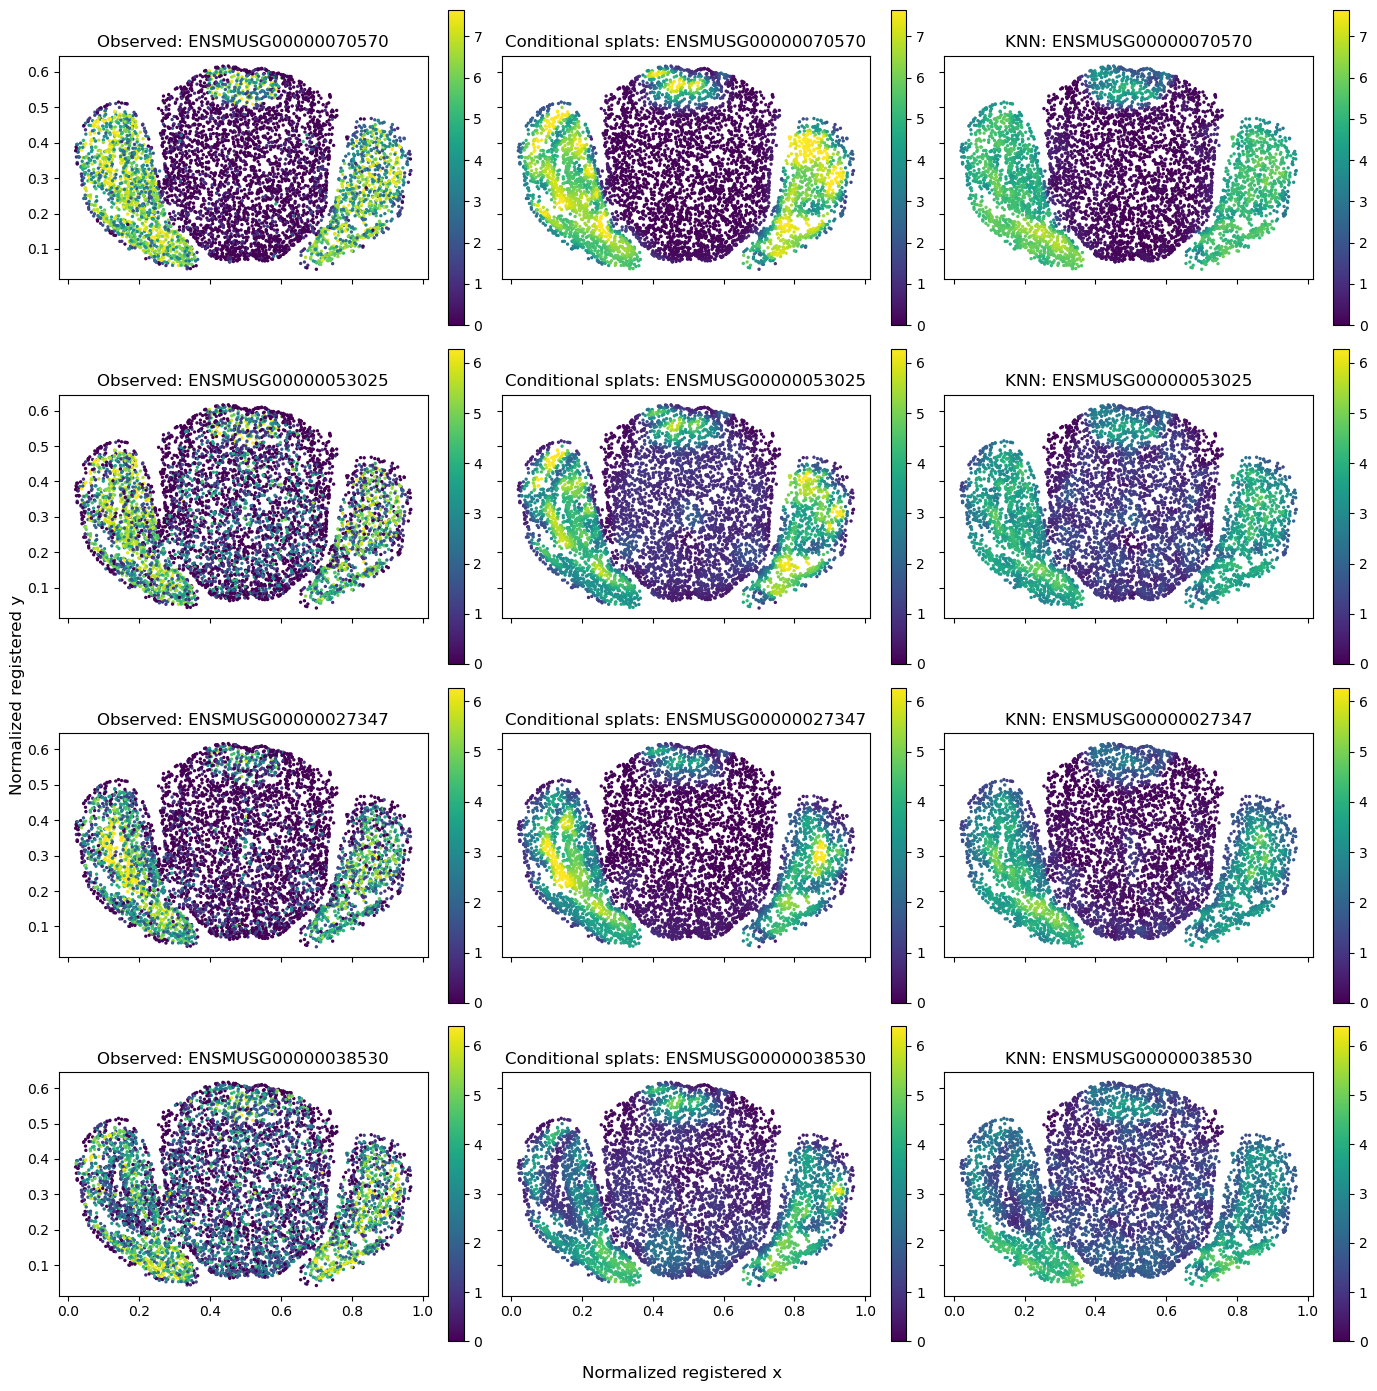

In [6]:
def evaluate_section(section, role):
    data, rows, predictions = cohort[section], [], {}
    for (kind, seed), model in models.items():
        pred = predict_field(model, data['xy'], data['depth'], batch_size=CONFIG['batch_size'])
        predictions[kind, seed] = pred
        rows.append(dict(section=section, role=role, model=kind, seed=seed,
                         **field_metrics(pred, data['expression'])))
    predictions['KNN', None] = knn_prediction(data['xy'], data['depth'])
    predictions['Constant training mean', None] = np.broadcast_to(constant_rate, data['expression'].shape)
    for kind in ['KNN', 'Constant training mean']:
        rows.append(dict(section=section, role=role, model=kind, seed=None,
                         **field_metrics(predictions[kind, None], data['expression'])))
    table = pd.DataFrame(rows)
    table.to_csv(RUN_DIR / f'{role}_{section}_metrics.csv', index=False)
    return table, predictions

training_tables = [evaluate_section(s, 'training')[0] for s in train_sections]
validation_results, validation_predictions = evaluate_section(validation_section, 'validation')
all_results = pd.concat(training_tables+[validation_results], ignore_index=True)
all_results.to_csv(RUN_DIR / 'training_validation_metrics.csv', index=False)
display(all_results.groupby(['role', 'section', 'model'])[
    ['expression_mae', 'profile_cosine', 'log_total_mae']].mean())

def plot_expression(section, predictions, name):
    data = cohort[section]
    fields = [('Observed', data['expression']),
              ('Conditional splats', predictions['Conditional splats', CONFIG['model_seeds'][0]]),
              ('KNN', predictions['KNN', None])]
    fig, axes = plt.subplots(len(plot_gene_indices), len(fields), figsize=(14, 3.5*len(plot_gene_indices)),
                              sharex=True, sharey=True, squeeze=False)
    for row, (gene, limit) in enumerate(zip(plot_gene_indices, plot_gene_limits)):
        for ax, (title, values) in zip(axes[row], fields):
            im = ax.scatter(*data['xy'].T, c=values[:, gene], s=2, cmap='viridis', vmin=0, vmax=limit,
                            rasterized=True)
            ax.set(title=f'{title}: {gene_names[gene]}', aspect='equal')
            fig.colorbar(im, ax=ax, fraction=0.04)
    fig.supxlabel('Normalized registered x')
    fig.supylabel('Normalized registered y')
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()
plot_expression(validation_section, validation_predictions, 'validation_gene_fields')


## Emit a field from depth alone

This cell does not read the validation expression or an inventory to emit splats. It supplies a scalar z coordinate, transformed using the training coordinate system. Any subsequent query grid only samples that emitted field.

Display the emitted centers/ellipses over measurement locations for context, but do not project them onto those locations. The support diagnostic below uses the validation coordinates **after generation** and is not a training penalty or a hard anatomical mask. Gaussian ellipses can extend outside support even when their centers are inside.


,emitted_splats,fraction_centers_outside_observation_support_proxy,median_distance_to_observations
0,256,0.01953,0.004592


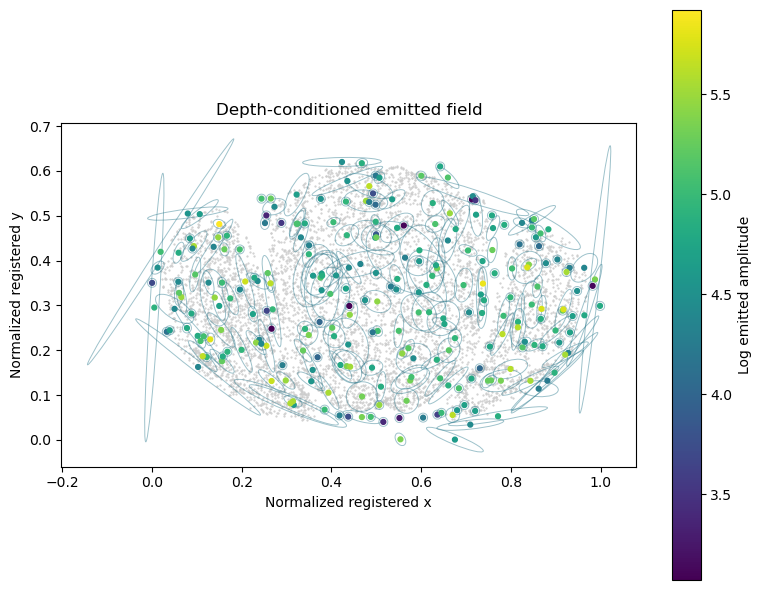

In [7]:
synthesis_model = models['Conditional splats', CONFIG['model_seeds'][0]]
def emit_at_z(z):
    depth = (float(z)-float(transform['z_origin']))/float(transform['z_scale'])
    return export_field(synthesis_model, depth)
emitted = emit_at_z(cohort[validation_section]['z'])
np.savez_compressed(RUN_DIR / f'emitted_{validation_section}.npz', **emitted)
from scipy.spatial import cKDTree
distance = cKDTree(cohort[validation_section]['xy']).query(emitted['means'])[0]
display(pd.DataFrame([{'emitted_splats': len(emitted['means']),
       'fraction_centers_outside_observation_support_proxy': float(np.mean(distance > CONFIG['support_radius'])),
       'median_distance_to_observations': float(np.median(distance))}]))
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(*cohort[validation_section]['xy'].T, s=0.3, color='#cccccc', rasterized=True)
for center, scales, angle in zip(emitted['means'], np.exp(emitted['log_scales']), emitted['rotation'][:, 0]):
    ax.add_patch(Ellipse(center, 2*scales[0], 2*scales[1], angle=np.degrees(angle),
                         facecolor='none', edgecolor='#28788c', linewidth=0.7, alpha=0.45))
im = ax.scatter(*emitted['means'].T, c=emitted['log_amplitudes'][:, 0], s=12, cmap='viridis')
fig.colorbar(im, ax=ax, label='Log emitted amplitude')
ax.set(title='Depth-conditioned emitted field', xlabel='Normalized registered x',
       ylabel='Normalized registered y', aspect='equal')
fig.tight_layout()
save_figure(fig, 'emitted_validation_splats')
plt.show()


## Conditional generation diagnostics

These validation-only diagnostics ask whether depth changes the generated field and whether rendered expression preserves spatial organization. Existing model checkpoints are reused. Only the depth-independent control is trained here, with the same architecture, initialization, seeds, loss, training sections, support penalty, and validation selection; its depth input is always zero.

Programs below are training-derived expression prototypes, not annotated cell types or the program numbering from other notebooks. Genes are selected by training variance, not validation performance. All spatial scores use identical occupied bins for observations and predictions. Missing bins are not biological zeros. Seeds are optimization repeats, not independent specimens.

Diagnostics have their own versioned directory so adding or changing these analyses does not invalidate the original field-training cache.


In [8]:
from paper.field_synthesis_diagnostics import (
    DepthIndependentGenerator, training_programs, spatial_metrics, common_grid,
)
DIAGNOSTIC_CONFIG = dict(n_genes=32, n_programs=8, seed=3107,
    bin_widths=[0.025, 0.05, 0.1], min_measurements=5, grid_resolution=96)
# Widths are in normalized registered xy, not micrometers.
diagnostic_manifest = dict(base_run=run_id, settings=DIAGNOSTIC_CONFIG,
    helper_sha256=hashlib.sha256(
        (PROJECT_ROOT / 'paper/field_synthesis_diagnostics.py').read_bytes()).hexdigest(),
    workflow_version=1)
diagnostic_id = hashlib.sha256(json.dumps(diagnostic_manifest, sort_keys=True).encode()).hexdigest()[:12]
DIAGNOSTIC_DIR = RUN_DIR / 'diagnostics' / diagnostic_id
DIAGNOSTIC_FIGURES = FIGURE_DIR / 'diagnostics' / diagnostic_id
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSTIC_FIGURES.mkdir(parents=True, exist_ok=True)
(DIAGNOSTIC_DIR / 'manifest.json').write_text(json.dumps(diagnostic_manifest, indent=2))
def save_diagnostic(fig, name):
    fig.savefig(DIAGNOSTIC_FIGURES / f'{name}.png', dpi=180, bbox_inches='tight', facecolor='white')
diagnostic_genes, diagnostic_programs = training_programs(training,
    n_genes=DIAGNOSTIC_CONFIG['n_genes'], n_programs=DIAGNOSTIC_CONFIG['n_programs'],
    seed=DIAGNOSTIC_CONFIG['seed'])
np.savez_compressed(DIAGNOSTIC_DIR / 'training_vocabulary.npz',
    gene_indices=diagnostic_genes, gene_names=np.asarray(gene_names[diagnostic_genes], dtype=str),
    prototypes=diagnostic_programs)
bin_origin = train_xy.min(0)
control_models = {}
for seed in CONFIG['model_seeds']:
    seed_all(seed)
    control = DepthIndependentGenerator(init2d, autoencoder.decoder, width=CONFIG['width'],
        slot_dim=CONFIG['slot_dim'], kernel_sharpness=CONFIG['kernel_sharpness']).to(device)
    path = DIAGNOSTIC_DIR / f'depth_independent_{seed}_best.pt'
    if REUSE_CHECKPOINTS and path.exists():
        print(f'Loading completed depth-independent control, seed {seed}', flush=True)
        saved = torch.load(path, map_location=device, weights_only=True)
        control.load_state_dict(saved['state_dict'])
        fit = saved['fit']
    else:
        print(f'Training fresh depth-independent control, seed {seed}', flush=True)
        def control_checkpoint(current, history):
            pd.DataFrame(history).to_csv(DIAGNOSTIC_DIR / f'depth_independent_{seed}_history.csv', index=False)
            torch.save(dict(state_dict=current.state_dict(), step=history[-1]['step']),
                       DIAGNOSTIC_DIR / f'depth_independent_{seed}_latest.pt')
        fit = train_field(control, training, validation, steps=CONFIG['steps'],
            batch_size=CONFIG['batch_size'], checkpoint_every=CONFIG['checkpoint_every'],
            lr=CONFIG['learning_rate'], seed=seed, cosine_weight=CONFIG['cosine_weight'],
            total_weight=CONFIG['total_weight'], support_weight=CONFIG['support_weight'],
            support_radius=CONFIG['support_radius'], on_checkpoint=control_checkpoint)
        torch.save(dict(state_dict=control.state_dict(), fit=fit), path)
    control.eval()
    control_models[seed] = control
    print(f"Control seed {seed}: selected step {fit['best_step']}")


Loading completed depth-independent control, seed 3107
Control seed 3107: selected step 6000
Loading completed depth-independent control, seed 3117
Control seed 3117: selected step 3000


### Does depth matter?

Hold validation query coordinates and targets fixed; vary only the conditional generator's depth. Alternative conditions are all training depths, never the test depth. Correct depth need not win every metric, but a consistent advantage over distant depths and the depth-independent control supports meaningful conditioning.

These comparisons use the full validation section, which includes checkpoint-selection observations. They are diagnostics, not independent tests. No alternative depth is selected to replace the correct condition.


expression_mae  profile_cosine  \
condition                        bin_width                                   
Correct depth                    0.025              0.4103          0.6704   
                                 0.05               0.4103          0.6704   
                                 0.1                0.4103          0.6704   
Training depth C57BL6J-638850.19 0.025              0.4344          0.6125   
                                 0.05               0.4344          0.6125   
                                 0.1                0.4344          0.6125   
Training depth C57BL6J-638850.24 0.025              0.4129          0.6563   
                                 0.05               0.4129          0.6563   
                                 0.1                0.4129          0.6563   
Training depth C57BL6J-638850.26 0.025              0.4198          0.6632   
                                 0.05               0.4198          0.6632   
                                 0.1                0.4198          0.6632   
Training depth C57BL6J-638850.28 0.025               0.439          0.6315   
                                 0.05                0.439          0.6315   
                                 0.1                 0.439          0.6315   
Training depth C57BL6J-638850.30 0.025              0.4535          0.5984   
                                 0.05               0.4535          0.5984   
                                 0.1                0.4535          0.5984   

                                            gene_spatial_correlation  \
condition                        bin_width                             
Correct depth                    0.025                        0.7101   
                                 0.05                         0.8035   
                                 0.1                          0.8542   
Training depth C57BL6J-638850.19 0.025                        0.4951   
                                 0.05                         0.5784   
                                 0.1                          0.6421   
Training depth C57BL6J-638850.24 0.025                        0.6745   
                                 0.05                         0.7712   
                                 0.1                          0.8269   
Training depth C57BL6J-638850.26 0.025                        0.6659   
                                 0.05                         0.7461   
                                 0.1                          0.7887   
Training depth C57BL6J-638850.28 0.025                        0.5155   
                                 0.05                          0.572   
                                 0.1                          0.6084   
Training depth C57BL6J-638850.30 0.025                        0.4135   
                                 0.05                          0.469   
                                 0.1                          0.5295   

                                            program_spatial_correlation  
condition                        bin_width                               
Correct depth                    0.025                           0.7052  
                                 0.05                            0.8122  
                                 0.1                             0.8488  
Training depth C57BL6J-638850.19 0.025                           0.5152  
                                 0.05                            0.5917  
                                 0.1                             0.6455  
Training depth C57BL6J-638850.24 0.025                           0.6681  
                                 0.05                            0.7658  
                                 0.1                             0.8004  
Training depth C57BL6J-638850.26 0.025                           0.6579  
                                 0.05                             0.753  
                                 0.1                             0.8022  
Traini

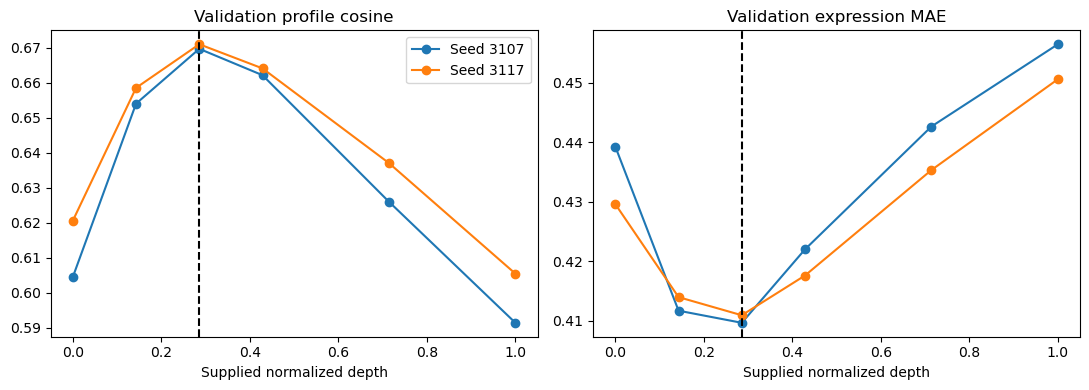

In [9]:
depth_rows = []
diagnostic_data = cohort[validation_section]
depth_conditions = [('Correct depth', float(diagnostic_data['depth']))] + [
    (f"Training depth {d['section']}", d['depth']) for d in training]
for seed in CONFIG['model_seeds']:
    model = models['Conditional splats', seed]
    for label, depth in depth_conditions:
        pred = predict_field(model, diagnostic_data['xy'], depth, batch_size=CONFIG['batch_size'])
        row = dict(seed=seed, condition=label, supplied_depth=depth,
                   depth_distance=abs(depth-float(diagnostic_data['depth'])),
                   **field_metrics(pred, diagnostic_data['expression']))
        for width in DIAGNOSTIC_CONFIG['bin_widths']:
            scores, _ = spatial_metrics(diagnostic_data['xy'], diagnostic_data['expression'],
                pred, diagnostic_genes, diagnostic_programs, origin=bin_origin,
                bin_width=width, min_measurements=DIAGNOSTIC_CONFIG['min_measurements'])
            depth_rows.append(dict(row, bin_width=width, **scores))
depth_results = pd.DataFrame(depth_rows)
depth_results.to_csv(DIAGNOSTIC_DIR / 'validation_depth_controls.csv', index=False)
display(depth_results.groupby(['condition', 'bin_width'])[
    ['expression_mae', 'profile_cosine', 'gene_spatial_correlation',
     'program_spatial_correlation']].mean())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for seed in CONFIG['model_seeds']:
    rows = depth_results[depth_results.seed == seed].drop_duplicates('condition').sort_values('supplied_depth')
    axes[0].plot(rows.supplied_depth, rows.profile_cosine, 'o-', label=f'Seed {seed}')
    axes[1].plot(rows.supplied_depth, rows.expression_mae, 'o-')
for ax, title in zip(axes, ['Validation profile cosine', 'Validation expression MAE']):
    ax.axvline(float(diagnostic_data['depth']), color='black', linestyle='--')
    ax.set(xlabel='Supplied normalized depth', title=title)
axes[0].legend()
fig.tight_layout()
save_diagnostic(fig, 'depth_response')
plt.show()


### Spatial organization and heterogeneity

Each square bin contains at least five measurements by default. Compare **mean expression**, not sums, so uneven sampling density does not directly set the signal. Each eligible bin has equal weight.

- Gene spatial correlation: agreement of spatial expression patterns for training-selected variable genes.
- Program spatial correlation: agreement of cosine-similarity maps to training-derived expression prototypes. These are scores, not mixture proportions.
- Variance ratio: predicted/observed spatial variance; one indicates matching variance, below one suggests lost heterogeneity. Correct variance alone does not imply correct localization.
- Co-expression MAE and correlation: agreement between gene-pair correlation matrices across bins. Shared anatomy can cause these associations; this is not evidence of regulation.

Report every predefined scale. Undefined correlations (including constant predictions) remain NaN, with valid counts retained in CSVs. No best scale, gene, program, or seed is selected from validation. The maps illustrate the first four training-defined prototypes; the numerical evaluation includes all prototypes.


,expression_mae,profile_cosine,log_total_mae
model,,,
Conditional splats,0.4103,0.6704,0.496
Constant training mean,0.5302,0.641,0.3595
Depth-independent splats,0.4141,0.6642,0.512
KNN,0.4632,0.7105,0.3394
MLP (Bio Objective),0.4071,0.642,0.5003
MLP-MAE,0.4029,0.5991,0.8514
Volumetric splats,0.4347,0.6775,0.4425


gene_spatial_correlation  \
model                    bin_width                             
Conditional splats       0.025                        0.7101   
                         0.05                         0.8035   
                         0.1                          0.8542   
Constant training mean   0.025                           NaN   
                         0.05                            NaN   
                         0.1                             NaN   
Depth-independent splats 0.025                        0.6654   
                         0.05                         0.7261   
                         0.1                          0.7436   
KNN                      0.025                        0.7509   
                         0.05                         0.8236   
                         0.1                          0.8614   
MLP (Bio Objective)      0.025                        0.5861   
                         0.05                         0.6565   
                         0.1                          0.6993   
MLP-MAE                  0.025                        0.5647   
                         0.05                         0.6359   
                         0.1                          0.6929   
Volumetric splats        0.025                        0.6571   
                         0.05                         0.7501   
                         0.1                          0.8046   

                                    program_spatial_correlation  \
model                    bin_width                                
Conditional splats       0.025                           0.7052   
                         0.05                            0.8122   
                         0.1                             0.8488   
Constant training mean   0.025                              NaN   
                         0.05                               NaN   
                         0.1                                NaN   
Depth-independent splats 0.025                            0.665   
                         0.05                            0.7387   
                         0.1                             0.7458   
KNN                      0.025                           0.7385   
                         0.05                            0.8371   
                         0.1                             0.8717   
MLP (Bio Objective)      0.025                           0.5985   
                         0.05                            0.6905   
                         0.1                              0.682   
MLP-MAE                  0.025                           0.5842   
                         0.05                            0.6773   
                         0.1                             0.6946   
Volumetric splats        0.025                           0.6321   
                         0.05                            0.7576   
                         0.1                             0.7768   

                                    variance_ratio_median  coexpression_mae  \
model                    bin_width                                            
Conditional splats       0.025                     0.9519            0.1146   
                         0.05                       1.172            0.1074   
                         0.1                        1.225            0.1122   
Constant training mean   0.025                          0               NaN   
                         0.05                           0               NaN   
                         0.1                            0               NaN   
Depth-independent splats 0.025                     0.7427            0.1544   
                         0.05                      0.9961            0.1446   
                         0.1                        1.165            0.1438   
KNN                      0.025                     0.5927           0.09536   
                         0.05                      0.7535            0.10

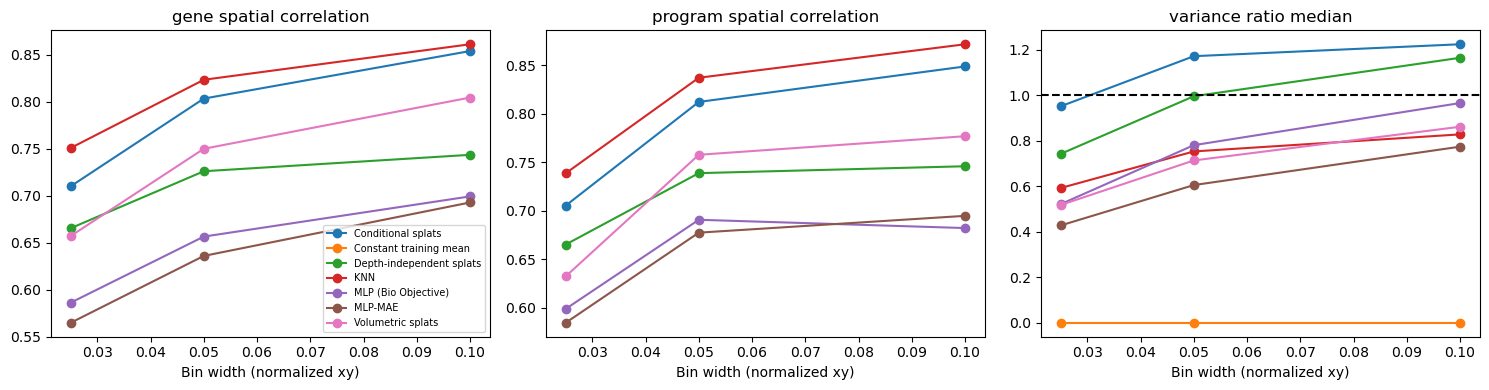

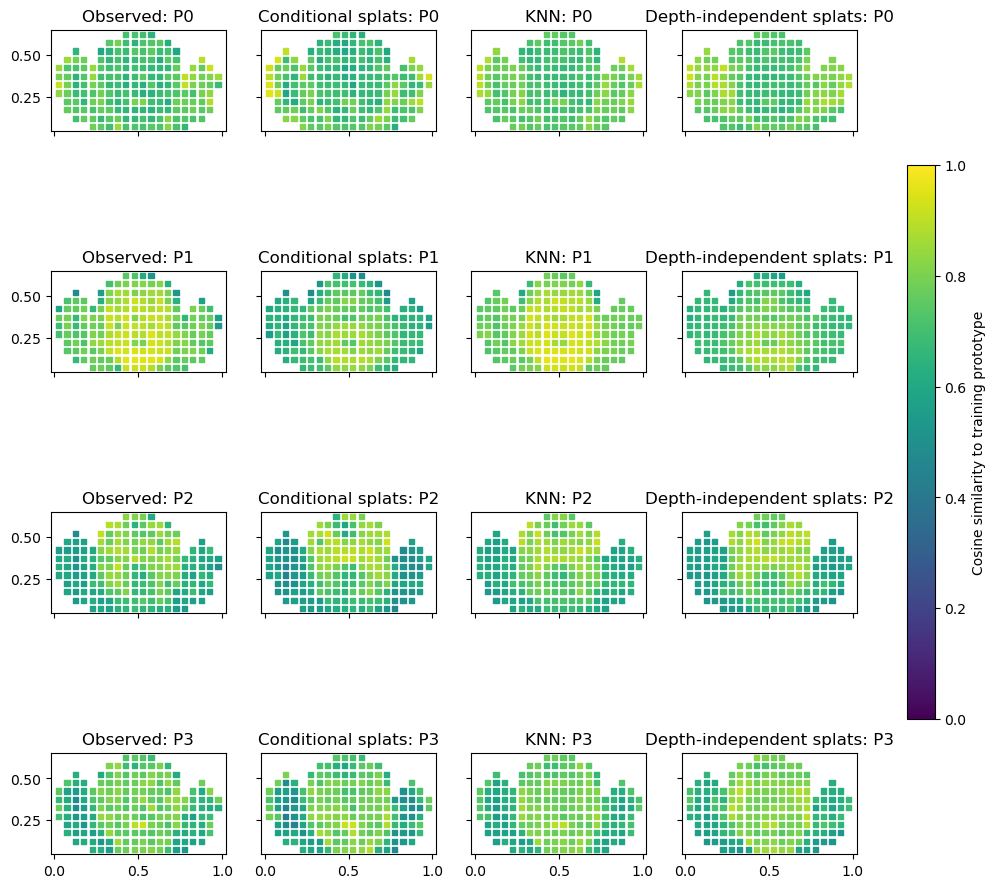

In [10]:
def evaluate_organization(section, predictions, role):
    data = cohort[section]
    local_predictions = dict(predictions)
    for seed, control in control_models.items():
        local_predictions['Depth-independent splats', seed] = predict_field(
            control, data['xy'], data['depth'], batch_size=CONFIG['batch_size'])
    rows, gene_rows, program_rows, raw_rows = [], [], [], []
    for (kind, seed), pred in local_predictions.items():
        raw_rows.append(dict(model=kind, seed=seed, **field_metrics(pred, data['expression'])))
        for width in DIAGNOSTIC_CONFIG['bin_widths']:
            scores, detail = spatial_metrics(data['xy'], data['expression'], pred,
                diagnostic_genes, diagnostic_programs, origin=bin_origin,
                bin_width=width, min_measurements=DIAGNOSTIC_CONFIG['min_measurements'])
            rows.append(dict(model=kind, seed=seed, bin_width=width, **scores))
            gene_rows.extend(dict(model=kind, seed=seed, bin_width=width,
                gene=str(gene_names[g]), correlation=float(c))
                for g, c in zip(diagnostic_genes, detail['gene_correlations']))
            program_rows.extend(dict(model=kind, seed=seed, bin_width=width,
                program=f'P{k}', correlation=float(c))
                for k, c in enumerate(detail['program_correlations']))
    result = pd.DataFrame(rows)
    result.to_csv(DIAGNOSTIC_DIR / f'{role}_organization.csv', index=False)
    pd.DataFrame(gene_rows).to_csv(DIAGNOSTIC_DIR / f'{role}_gene_patterns.csv', index=False)
    pd.DataFrame(program_rows).to_csv(DIAGNOSTIC_DIR / f'{role}_program_patterns.csv', index=False)
    pd.DataFrame(raw_rows).to_csv(DIAGNOSTIC_DIR / f'{role}_expression_controls.csv', index=False)
    display(pd.DataFrame(raw_rows).groupby('model')[[
        'expression_mae', 'profile_cosine', 'log_total_mae']].mean())
    display(result.groupby(['model', 'bin_width'])[[
        'gene_spatial_correlation', 'program_spatial_correlation',
        'variance_ratio_median', 'coexpression_mae', 'coexpression_correlation']].mean())
    return result, local_predictions

organization_results, organization_predictions = evaluate_organization(
    validation_section, validation_predictions, 'validation')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for kind, group in organization_results.groupby('model'):
    means = group.groupby('bin_width').mean(numeric_only=True)
    for ax, metric in zip(axes, ['gene_spatial_correlation',
                                'program_spatial_correlation', 'variance_ratio_median']):
        ax.plot(means.index, means[metric], 'o-', label=kind)
        ax.set(xlabel='Bin width (normalized xy)', title=metric.replace('_', ' '))
axes[2].axhline(1, color='black', linestyle='--')
axes[0].legend(fontsize=7)
fig.tight_layout()
save_diagnostic(fig, 'organization_by_scale')
plt.show()

# Fixed middle scale for display only, not selected by its performance.
map_width = DIAGNOSTIC_CONFIG['bin_widths'][1]
map_fields = [('Observed', diagnostic_data['expression']),
    ('Conditional splats', organization_predictions['Conditional splats', CONFIG['model_seeds'][0]]),
    ('KNN', organization_predictions['KNN', None]),
    ('Depth-independent splats', organization_predictions['Depth-independent splats', CONFIG['model_seeds'][0]])]
fig, axes = plt.subplots(4, 4, figsize=(13, 12), sharex=True, sharey=True)
for col, (label, pred) in enumerate(map_fields):
    _, detail = spatial_metrics(diagnostic_data['xy'], diagnostic_data['expression'], pred,
        diagnostic_genes, diagnostic_programs, origin=bin_origin, bin_width=map_width,
        min_measurements=DIAGNOSTIC_CONFIG['min_measurements'])
    for k in range(4):
        im = axes[k, col].scatter(*detail['bin_centers'].T,
            c=detail['predicted_program_scores'][:, k], s=14, marker='s',
            cmap='viridis', vmin=0, vmax=1)
        axes[k, col].set(title=f'{label}: P{k}', aspect='equal')
fig.colorbar(im, ax=axes.ravel().tolist(), label='Cosine similarity to training prototype', shrink=0.6)
save_diagnostic(fig, 'validation_program_maps')
plt.show()


### Common-grid rendering without a held-out silhouette

All fields are rendered on the same training-bounds rectangle, padded by five percent. No validation coordinates, tissue mask, or observed silhouette selects the displayed pixels. Columns span the minimum training depth, validation depth, and maximum training depth; test depth is not used.

Color limits and genes remain training-defined. Observation panels above are separate comparisons. The model generates expression, not a tissue-occupancy mask. Normalized responsibilities can yield nonzero expression far from measurements; extrapolated signal outside tissue is not evidence of generated anatomy. Training support constrains centers softly, not the entire rendered field.


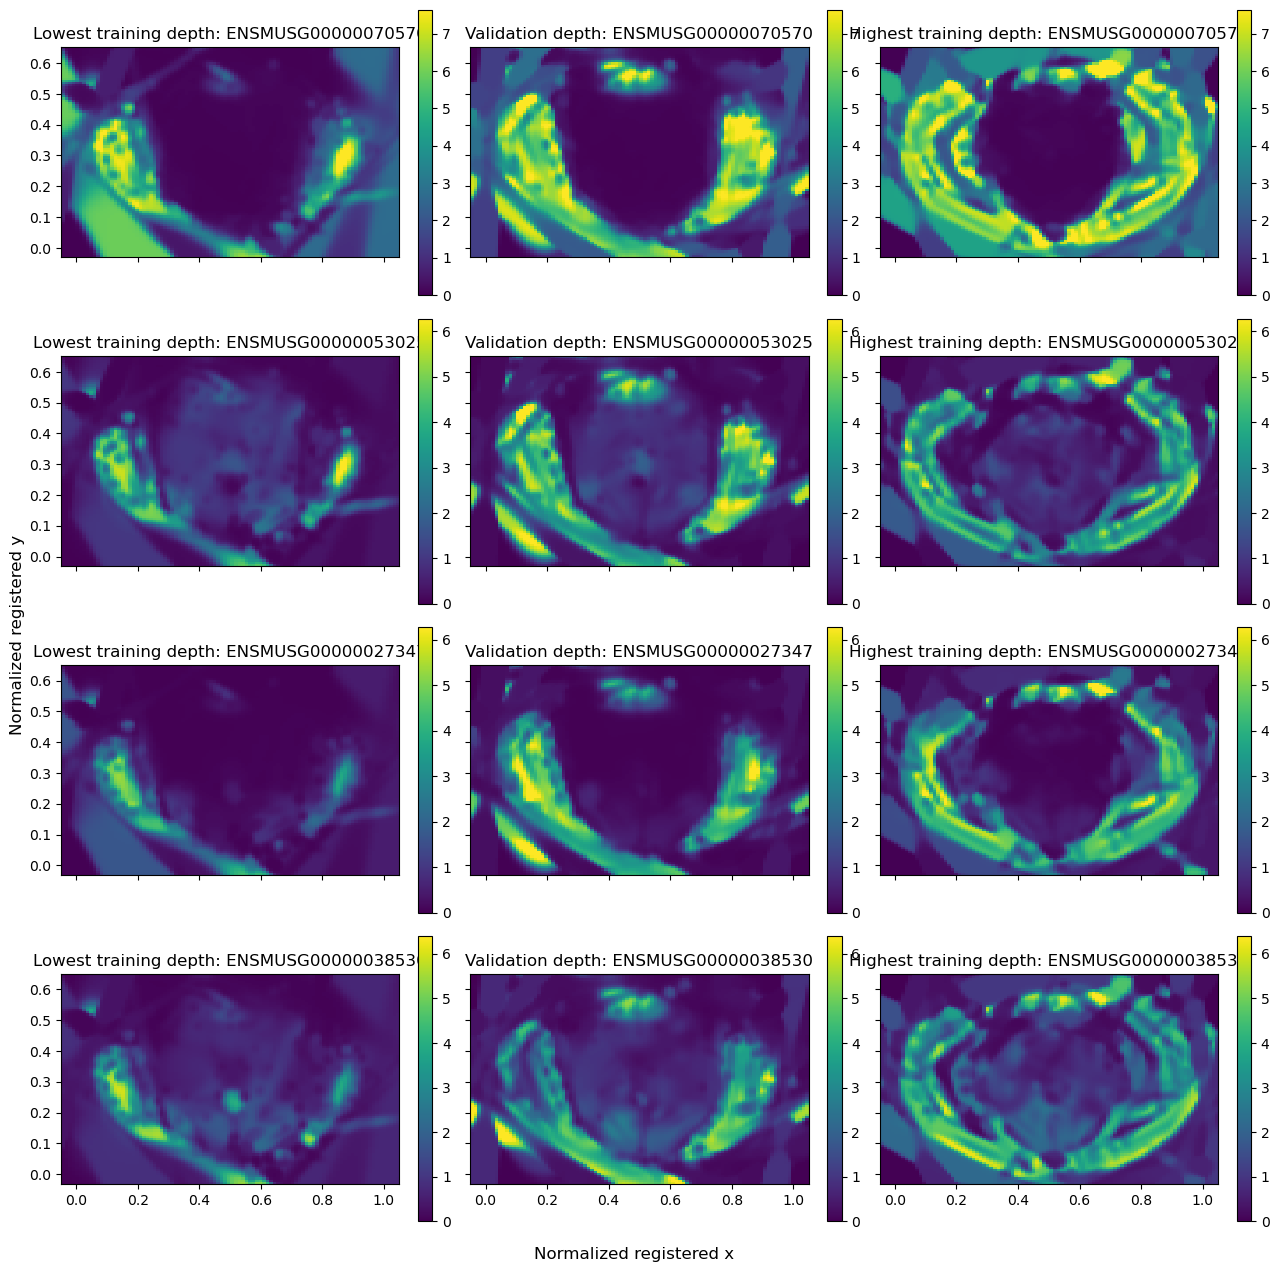

In [11]:
grid, grid_low, grid_high = common_grid(train_xy, resolution=DIAGNOSTIC_CONFIG['grid_resolution'])
grid_depths = [min(d['depth'] for d in training), float(diagnostic_data['depth']),
               max(d['depth'] for d in training)]
grid_labels = ['Lowest training depth', 'Validation depth', 'Highest training depth']
resolution = DIAGNOSTIC_CONFIG['grid_resolution']
grid_fields = [predict_field(synthesis_model, grid, depth, batch_size=CONFIG['batch_size'])
               for depth in grid_depths]
np.savez_compressed(DIAGNOSTIC_DIR / 'common_grid_fields.npz', xy=grid,
    depths=np.asarray(grid_depths), expression=np.stack(grid_fields))
fig, axes = plt.subplots(len(plot_gene_indices), len(grid_depths),
    figsize=(13, 3.2*len(plot_gene_indices)), squeeze=False, sharex=True, sharey=True)
for row, (gene, limit) in enumerate(zip(plot_gene_indices, plot_gene_limits)):
    for col, (label, values) in enumerate(zip(grid_labels, grid_fields)):
        im = axes[row, col].imshow(values[:, gene].reshape(resolution, resolution),
            origin='lower', extent=[grid_low[0], grid_high[0], grid_low[1], grid_high[1]],
            cmap='viridis', vmin=0, vmax=limit, interpolation='nearest', aspect='equal')
        axes[row, col].set(title=f'{label}: {gene_names[gene]}')
        fig.colorbar(im, ax=axes[row, col], fraction=0.04)
fig.supxlabel('Normalized registered x')
fig.supylabel('Normalized registered y')
fig.tight_layout()
save_diagnostic(fig, 'common_grid_gene_fields')
plt.show()


## Frozen test evaluation

Enable `RUN_TEST` only after freezing the configuration and KNN choice. This uses the test depth and query coordinates to evaluate a field, not test profiles to generate it. No model fitting, tissue projection, or checkpoint selection occurs here.


,expression_mae,profile_cosine,log_total_mae
model,,,
Conditional splats,0.4178,0.694,0.4469
Constant training mean,0.5334,0.6604,0.3661
Depth-independent splats,0.4254,0.6669,0.5016
KNN,0.4745,0.7263,0.3298
MLP (Bio Objective),0.4126,0.6643,0.467
MLP-MAE,0.4101,0.6245,0.7422
Volumetric splats,0.4427,0.7041,0.3893


gene_spatial_correlation  \
model                    bin_width                             
Conditional splats       0.025                        0.6775   
                         0.05                         0.7497   
                         0.1                          0.8155   
Constant training mean   0.025                           NaN   
                         0.05                            NaN   
                         0.1                             NaN   
Depth-independent splats 0.025                        0.5853   
                         0.05                         0.6543   
                         0.1                          0.7186   
KNN                      0.025                        0.7136   
                         0.05                         0.7883   
                         0.1                          0.8651   
MLP (Bio Objective)      0.025                        0.5696   
                         0.05                         0.6457   
                         0.1                          0.7439   
MLP-MAE                  0.025                        0.5535   
                         0.05                         0.6273   
                         0.1                          0.7161   
Volumetric splats        0.025                        0.6352   
                         0.05                         0.7184   
                         0.1                          0.8114   

                                    program_spatial_correlation  \
model                    bin_width                                
Conditional splats       0.025                           0.6396   
                         0.05                             0.701   
                         0.1                             0.7828   
Constant training mean   0.025                              NaN   
                         0.05                               NaN   
                         0.1                                NaN   
Depth-independent splats 0.025                           0.5531   
                         0.05                            0.6235   
                         0.1                             0.7023   
KNN                      0.025                           0.6444   
                         0.05                            0.7187   
                         0.1                             0.8284   
MLP (Bio Objective)      0.025                           0.5259   
                         0.05                            0.6244   
                         0.1                              0.768   
MLP-MAE                  0.025                           0.5387   
                         0.05                            0.6357   
                         0.1                             0.7742   
Volumetric splats        0.025                           0.5663   
                         0.05                            0.6608   
                         0.1                               0.79   

                                    variance_ratio_median  coexpression_mae  \
model                    bin_width                                            
Conditional splats       0.025                     0.9078            0.1041   
                         0.05                       1.063           0.09053   
                         0.1                        1.198            0.1053   
Constant training mean   0.025                          0               NaN   
                         0.05                           0               NaN   
                         0.1                            0               NaN   
Depth-independent splats 0.025                      0.739            0.1788   
                         0.05                      0.9763            0.1489   
                         0.1                        1.145            0.1513   
KNN                      0.025                     0.6088           0.09429   
                         0.05                      0.7561           0.083

expression_mae           profile_cosine           \
                                 mean       std           mean      std   
model                                                                     
Conditional splats             0.4178 0.0002924          0.694 0.002083   
Constant training mean         0.5334       NaN         0.6604      NaN   
KNN                            0.4745       NaN         0.7263      NaN   
MLP (Bio Objective)            0.4126 0.0004883         0.6643 0.002155   
MLP-MAE                        0.4101  0.002183         0.6245 0.004177   
Volumetric splats              0.4427 0.0003576         0.7041  2.2e-05   

                       log_total_mae           
                                mean      std  
model                                          
Conditional splats            0.4469 0.008109  
Constant training mean        0.3661      NaN  
KNN                           0.3298      NaN  
MLP (Bio Objective)            0.467  0.01336  
MLP-MAE                       0.7422   0.0166  
Volumetric splats             0.3893 0.001974

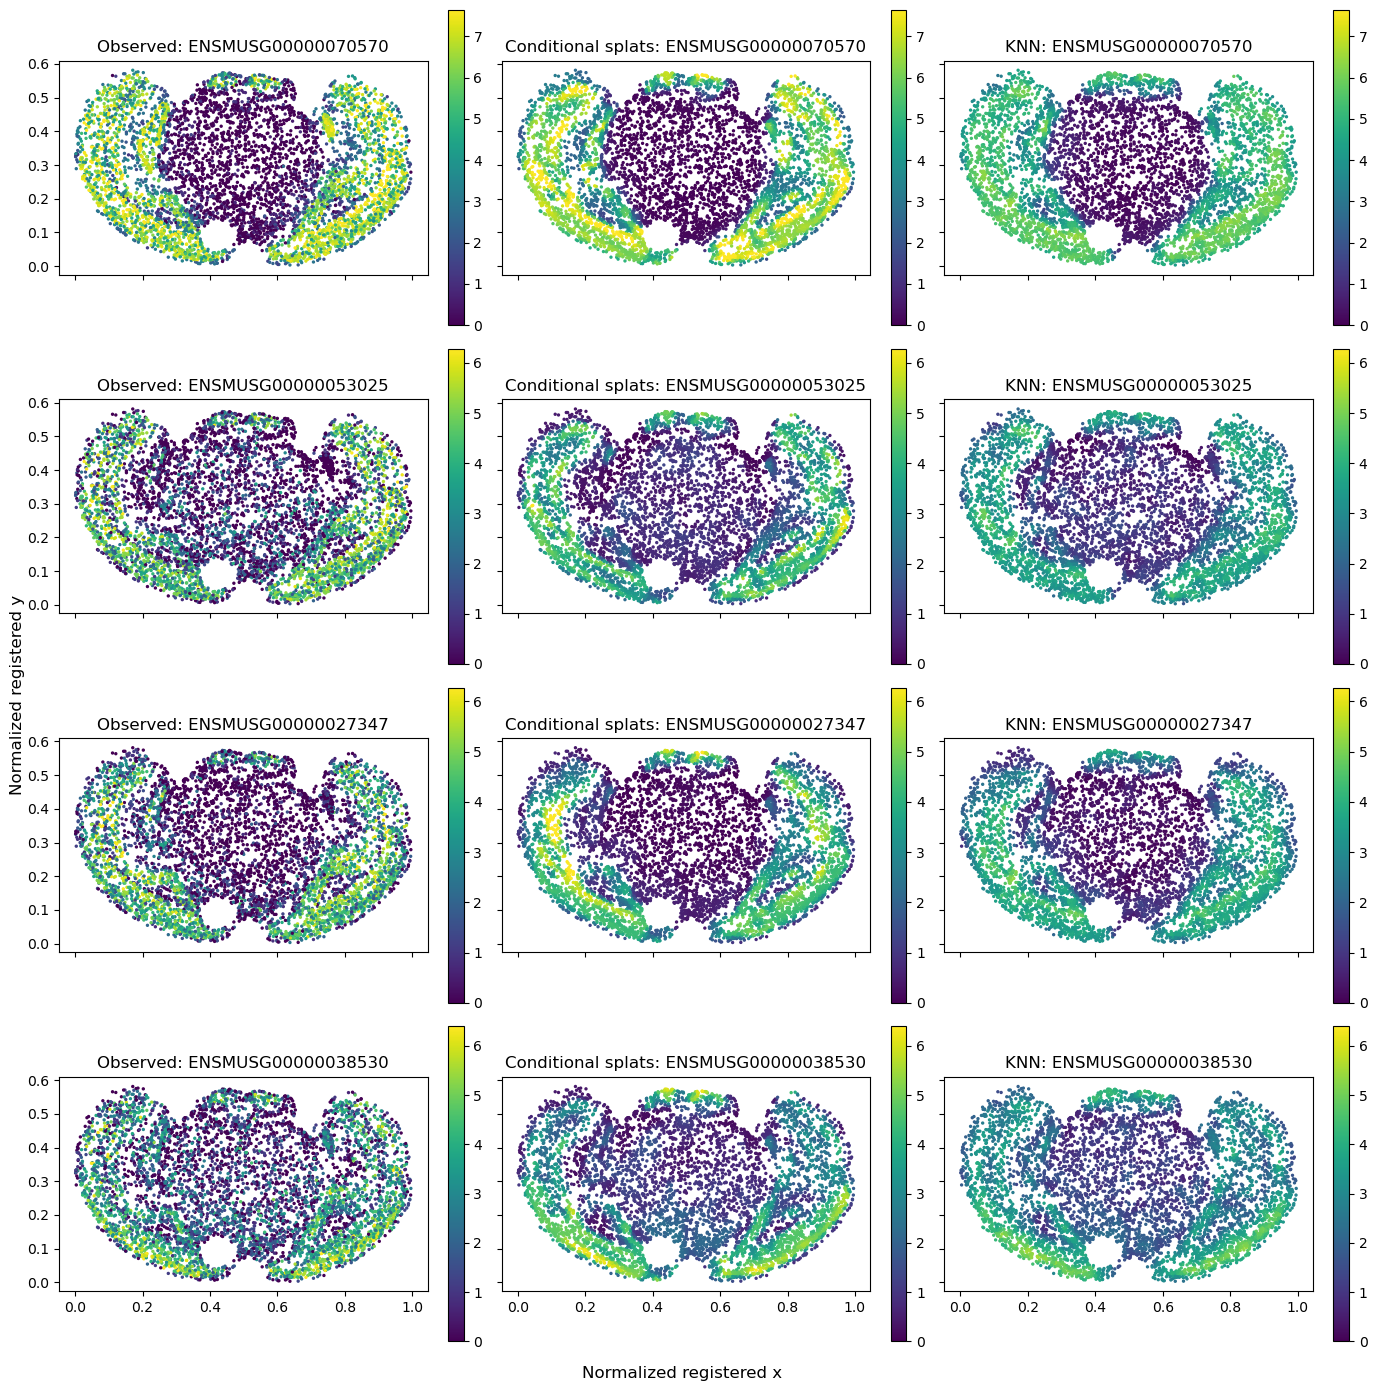

In [12]:
if RUN_TEST:
    test_results, test_predictions = evaluate_section(test_section, 'test')
    test_organization, _ = evaluate_organization(test_section, test_predictions, 'test')
    display(test_results.groupby('model')[['expression_mae', 'profile_cosine', 'log_total_mae']].agg(['mean', 'std']))
    plot_expression(test_section, test_predictions, 'test_gene_fields')
    np.savez_compressed(RUN_DIR / f'emitted_{test_section}.npz', **emit_at_z(cohort[test_section]['z']))
else:
    print('Test evaluation is disabled. Freeze settings using validation before enabling RUN_TEST.')
